# 5.4 - Gradient boosting: can a flexible model find what a linear one cannot?

> **Needs:** notebooks 5.2 and 5.3; the optional `ml` dependency group (LightGBM, Optuna); the database.
>
> **Produces:** walk-forward predictions in the artifact store and the registered trials of the searches.

Notebook 5.3 combined the 45 features of 5.2 with four penalised linear models. A linear model can only add up the
features' effects, each in a straight line. **Gradient-boosted trees** can follow curves (the effect of volatility may
matter only at the extremes) and interactions (momentum may work only among small companies) - the reason they win
most competitions on tabular data, and the model *Machine Learning for Trading* (chapter 12) puts at the centre of its
equity case studies.

The question is the same as 5.3's: out of sample, 2015-2024, inside the same folds, does it beat the plain average of
issuance and ROCE - and the linear models? The comparison also includes notebook 3.3's learned value score (the
book-style boosted model of Damon Lee's ratios, predicting a year ahead).

## How gradient boosting works

A **regression tree** splits the companies by asking yes/no questions about their features ("is volatility above its
70th percentile?"), and predicts the average target of the companies in each final group (a *leaf*). One tree is a
crude, jumpy model. **Boosting** (Friedman, 2001) builds many small trees one after another, each fitted to what the
trees before it got wrong, and adds them up with a small weight $\nu$ (the *learning rate*):
$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x), \qquad h_m \text{ fitted to the errors (more exactly, the negative gradient of the loss) of } F_{m-1}.$$
Small trees, a small $\nu$ and many rounds give a smooth model that can still bend where the data bend. LightGBM (Ke
et al., 2017) is a fast implementation: it bins each feature into a histogram and grows trees leaf by leaf.

The settings that control how closely it fits are the number of **leaves** per tree (how many questions combine: 4
leaves can capture a two-feature interaction), the **least companies a leaf may hold** (a leaf of 1,000 company-months
is an average worth trusting), the number of trees, the learning rate, the share of rows and features each tree sees
(randomness that decorrelates the trees), and an L2 penalty on the leaf values.

The **loss** decides what "wrong" means:

| Loss | Minimises | Why consider it |
|---|---|---|
| Squared error | $\sum (y - F)^2$ | predicts the mean - what a portfolio is paid |
| Huber | squared for errors below $\delta$ = 0.05, linear beyond | an extreme month pulls the fit less |
| LambdaRank (Burges, 2010) | a smooth version of how badly each month's *ordering* is wrong, weighted towards the top | learns the ranking directly; each month a group, each company labelled by its quintile |

**SHAP values** (Lundberg et al., 2020) explain a fitted tree model exactly: each prediction is split into a baseline
plus one contribution per feature, and the contributions add up to the prediction. The average absolute contribution
of a feature is its importance; unlike the coefficients of 5.3, it captures curves and interactions too.

## The protocol, fixed before any result

| Choice | Setting |
|---|---|
| Inputs, target, folds | exactly 5.3's: the 45 features as centred percentiles, next month's trimmed excess return, test 2015-2024 on ten-year windows |
| Shared settings | 300 trees, learning rate 0.03, 70 % of rows and features per tree, L2 penalty 1 |
| Grid | 3 losses (squared, Huber, LambdaRank) x 3 leaf profiles (4 leaves of at least 1,000 rows; 16 of 500; 64 of 200), tuned inside each fold by purged 5-fold cross-validation on mean rank IC (a month a model ranks nobody scores 0) |
| Optuna | 40 trials of a Bayesian (TPE) search over leaves, leaf size, learning rate, trees, row and feature shares and the penalty, for the loss that scored best in the 2015 fold's tuning, on the 2005-2014 window only; the best settings are refitted in every fold, not retuned |
| Judged by | out-of-sample rank IC against next month's return 2015-2024; differences from the composite and from each linear model, with t-statistics |
| Registered | every grid point, every Optuna trial and both out-of-sample results, in the new family `ml4t_gbm_monthly` |

In [1]:
import pandas as pd
from IPython.display import display

from equity_research.data import artifacts as store
from equity_research.data.cache import ResearchCache
from equity_research.data.universe import load_universe_data
from equity_research.ml import boosting as gb
from equity_research.ml import linear as ln
from equity_research.ml.features import unstack
from equity_research.strategies import learned_value as ml
from research_core import charts
from research_core.analytics.signals import evaluation as ev
from research_core.analytics.signals import labels as lb
from research_core.analytics.signals import validation as va
from research_core.data.db.engine import get_engine
from research_core.engine.registry import record_search, trial_count

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
FIRST_TEST, LAST_TEST, TRAIN_YEARS, OPTUNA_TRIALS = 2015, 2024, 10, 40
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
FEATURES = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
long = store.load("features", "company_month_end", FEATURES, snapshot=SNAPSHOT)
assert long is not None, "run notebook 5.2 first: it builds the features for this data snapshot"
monthly = store.cached(
    "labels",
    "fwd_ret_month",
    {"universe": UNIVERSE, "start": START, "end": END, "dates": "rebalances"},
    lambda: lb.period_returns(data.returns, dates),
    snapshot=SNAPSHOT,
)
x = ln.centred_ranks(long)
y = lb.trimmed_excess(monthly, data.members)
ends = va.next_date_ends(dates)
folds = va.walk_forward(dates, ends, train_years=TRAIN_YEARS, first_test=FIRST_TEST, last_test=LAST_TEST)
STUDY = FEATURES | {
    "target": "trimmed excess, 1 %",
    "train_years": TRAIN_YEARS,
    "first_test": FIRST_TEST,
    "flat": "ic 0",
}
print(f"{x.shape[1]} features, {len(x):,} member-months; {len(folds)} folds")

left out 1078 facts of 2 companies in ['GBP']


45 features, 360,287 member-months; 10 folds


## Step 1 - the grid, tuned inside each fold

Nine configurations, each scored on each fold's training years by purged cross-validation; the best refitted and
scoring the test year. Kept in the artifact store.

In [2]:
configs = gb.grid()
grid_run = gb.stored_walk_forward(x, y, folds, ends, configs, name="grid", config=STUDY, snapshot=SNAPSHOT)
print("Configuration chosen in each fold")
display(grid_run.chosen.to_frame().T)
print("Mean validation IC of each configuration, averaged over the ten folds' tuning")
display(grid_run.tuning.mean().sort_values(ascending=False).to_frame("mean validation IC").T.style.format("{:+.4f}"))

Configuration chosen in each fold


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
config,huber/large,huber/large,huber/large,huber/large,huber/large,huber/large,huber/large,huber/large,huber/large,huber/large


Mean validation IC of each configuration, averaged over the ten folds' tuning


,huber/large,huber/medium,l2/large,l2/medium,huber/small,l2/small,rank/large,rank/medium,rank/small
mean validation IC,+0.0463,+0.0418,+0.0369,+0.0360,+0.0315,+0.0256,-0.0055,-0.0057,-0.0106


## Step 2 - Optuna, on the years before the first test only

The loss of the configuration that won the 2015 fold's tuning is searched further: 40 trials, each scored by the same
purged cross-validation on 2005-2014. The test years 2015-2024 play no part.

In [3]:
first_year = min(grid_run.tuning.index)
loss = gb.grid()[str(grid_run.tuning.loc[first_year].idxmax())].loss
trials, best = gb.stored_search(
    x, y, folds[0].train, ends, loss=loss, n_trials=OPTUNA_TRIALS, config=STUDY, snapshot=SNAPSHOT
)
print(f"Loss searched: {loss}. Best of {len(trials)} trials:")
display(
    trials.sort_values("validation_ic", ascending=False)
    .head(8)
    .style.format(
        {
            "learning_rate": "{:.4f}",
            "subsample": "{:.2f}",
            "colsample_bytree": "{:.2f}",
            "reg_lambda": "{:.3f}",
            "validation_ic": "{:+.4f}",
        }
    )
)
tuned_run = gb.stored_walk_forward(x, y, folds, ends, {"optuna": best}, name="optuna", config=STUDY, snapshot=SNAPSHOT)

C:\SourceCode\QuantResearch\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loss searched: huber. Best of 40 trials:


,num_leaves,min_child_samples,learning_rate,n_estimators,subsample,colsample_bytree,reg_lambda,validation_ic
34,60,162,0.0156,750,0.69,0.44,0.839,+0.0494
33,53,193,0.0165,650,0.85,0.49,0.107,+0.0490
39,60,116,0.0258,750,0.67,0.39,0.988,+0.0485
25,55,157,0.0135,750,0.79,0.35,0.193,+0.0483
27,58,152,0.0173,650,0.90,0.32,0.126,+0.0482
32,54,166,0.0197,700,0.98,0.36,0.026,+0.0482
28,37,177,0.0210,650,0.78,0.42,0.197,+0.0478
36,45,244,0.0247,650,0.90,0.31,0.210,+0.0477


## Step 3 - out of sample, 2015-2024, against everything before it

The two boosted runs, the four linear models of 5.3 (read back from the artifact store), the composite of issuance
and ROCE, and notebook 3.3's learned value score. Then each boosted run's monthly IC less the composite's and less each
linear model's, with t-statistics.

*Caution about the composite:* its two parts were picked by 5.2's triage over 2005-2024, which includes these test
years, so its result here is flattered by hindsight. The models' results are not.

In [4]:
linear_runs = {
    name: ln.stored_walk_forward(x, y, folds, ends, model, name=name, config=STUDY, snapshot=SNAPSHOT)
    for name, model in ln.MODELS.items()
}
panels = unstack(long)
test_dates = dates[(dates.year >= FIRST_TEST) & (dates.year <= LAST_TEST)]
learned = ml.learned_value(data.ratios, data.returns, data.members, dates)
scores = (
    {"GBM, grid": grid_run.scores, "GBM, Optuna": tuned_run.scores}
    | {ln.MODELS[n].label: r.scores for n, r in linear_runs.items()}
    | {
        "Composite (issuance + ROCE)": ln.composite(
            {"issuance": -panels["share_change"], "ROCE": panels["ROCE"]}, data.members
        ).loc[test_dates],
        "Learned value (3.4)": learned.loc[test_dates],
    }
)
ics = pd.DataFrame({name: ev.ic_series(s, monthly, data.members) for name, s in scores.items()}).loc[test_dates]
table = ev.ic_summary(ics, lags=0)[["mean", "t_nw", "positive"]]
table["spread"] = [ev.quantile_spread(ev.quantile_returns(s, monthly, data.members)).mean() for s in scores.values()]
table["turnover"] = [ev.top_turnover(s.loc[test_dates], data.members).mean() for s in scores.values()]
display(
    table.style.format(
        {"mean": "{:+.4f}", "t_nw": "{:+.2f}", "positive": "{:.0%}", "spread": "{:+.2%}", "turnover": "{:.0%}"}
    )
)
against = [c for c in ics.columns if not c.startswith("GBM")]
versus = pd.DataFrame(
    {(g, other): ln.ic_difference(ics[g], ics[other]) for g in ("GBM, grid", "GBM, Optuna") for other in against}
).T
print("Each boosted run's monthly IC less another score's")
display(versus.style.format({"mean difference": "{:+.4f}", "t_nw": "{:+.2f}", "dates": "{:.0f}"}))

,mean,t_nw,positive,spread,turnover
"GBM, grid",+0.0276,+2.75,58%,+0.57%,53%
"GBM, Optuna",+0.0274,+2.69,59%,+0.67%,53%
Ridge,+0.0150,+1.81,65%,+0.33%,37%
Lasso,+0.0057,+0.62,56%,+0.06%,32%
Elastic net,+0.0090,+0.94,60%,+0.21%,34%
Logistic regression,+0.0245,+2.81,66%,+0.34%,35%
Composite (issuance + ROCE),+0.0252,+3.21,66%,+0.36%,8%
Learned value (3.4),+0.0064,+0.76,49%,+0.27%,17%


Each boosted run's monthly IC less another score's


Mean rank IC by year


,"GBM, grid","GBM, Optuna",Ridge,Lasso,Elastic net,Logistic regression,Composite (issuance + ROCE),Learned value (3.4)
2015,+0.078,+0.074,+0.023,+0.001,+0.023,+0.040,+0.025,-0.009
2016,+0.036,+0.031,+0.045,+0.057,+0.045,+0.003,-0.025,+0.044
2017,+0.029,+0.030,+0.009,-0.041,-0.041,+0.029,+0.058,+0.006
2018,+0.011,+0.010,+0.015,+0.022,+0.007,+0.021,-0.007,-0.005
2019,+0.070,+0.070,-0.003,-0.035,-0.004,+0.028,+0.033,+0.001
2020,+0.047,+0.051,-0.012,-0.013,-0.010,-0.021,-0.006,+0.034
2021,+0.036,+0.034,+0.033,+0.040,+0.038,+0.053,+0.050,-0.005
2022,+0.008,+0.013,+0.030,+0.030,+0.029,+0.027,+0.028,+0.006
2023,-0.014,-0.016,+0.023,+0.010,+0.016,+0.061,+0.085,+0.022
2024,-0.028,-0.027,-0.016,-0.016,-0.016,+0.003,+0.009,-0.032


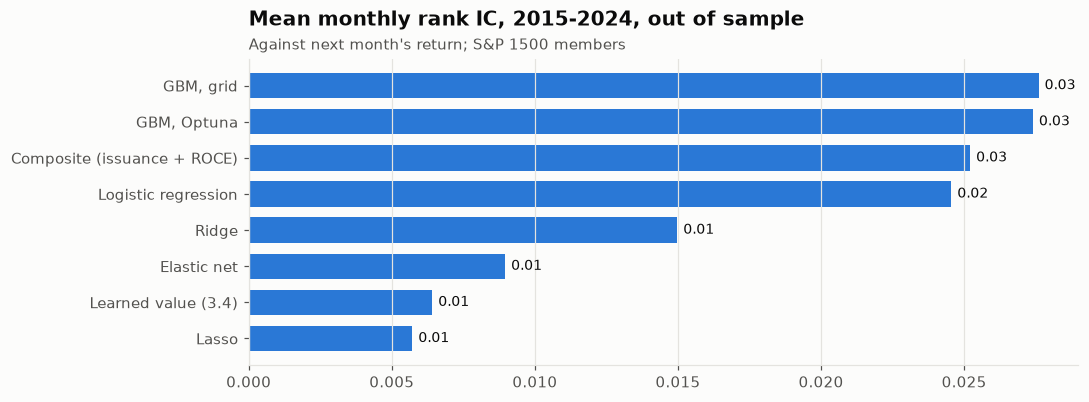

In [5]:
yearly = ics.groupby(ics.index.year).mean()
print("Mean rank IC by year")
display(yearly.style.format("{:+.3f}").background_gradient(cmap="RdYlGn", vmin=-0.08, vmax=0.08, axis=None))
fig = charts.ranked_bars(
    table["mean"],
    "Mean monthly rank IC, 2015-2024, out of sample",
    subtitle="Against next month's return; S&P 1500 members",
)

## Step 4 - what the boosted models lean on: SHAP

Each feature's mean absolute SHAP contribution on each test year, averaged over the ten folds, and how consistently it
ranks among the most important: the share of folds in which it is in the top ten.

In [6]:
for label, run in (("grid", grid_run), ("Optuna", tuned_run)):
    shap = run.shap
    top10 = shap.rank(axis=1, ascending=False) <= 10
    importance = pd.DataFrame({"mean |SHAP|": shap.mean(), "in top 10": top10.mean()}).sort_values(
        "mean |SHAP|", ascending=False
    )
    print(f"GBM, {label}: the 15 most important features (mean |SHAP|, in units of next month's excess return)")
    display(importance.head(15).style.format({"mean |SHAP|": "{:.5f}", "in top 10": "{:.0%}"}))

GBM, grid: the 15 most important features (mean |SHAP|, in units of next month's excess return)


,mean |SHAP|,in top 10
zero_days_3m,0.00226,100%
ffd_price,0.00219,100%
garch_vol,0.00102,100%
mom_12_1,0.00076,90%
ret_1m,0.00075,90%
beta_1y,0.00072,50%
vol_1y,0.00060,80%
sales_growth,0.00056,70%
ret_1w,0.00046,30%
Book Equity/TL,0.00044,50%


GBM, Optuna: the 15 most important features (mean |SHAP|, in units of next month's excess return)


,mean |SHAP|,in top 10
zero_days_3m,0.00223,100%
ffd_price,0.00206,100%
garch_vol,0.00100,100%
ret_1m,0.00075,90%
mom_12_1,0.00071,80%
vol_1y,0.00061,80%
beta_1y,0.00058,50%
sales_growth,0.00053,60%
ret_1w,0.00048,30%
Book Equity/TL,0.00043,30%


## Step 5 - how uncertain a single prediction is: conformal intervals

As in 5.3, for the boosted model with the squared-error loss and the medium leaf profile (a ranking loss predicts no
return, so it has no interval).

In [7]:
bands = gb.conformal(x, y, folds, ends, gb.grid()["l2/medium"])
display(
    bands.style.format(
        {"half-width": "{:.2%}", "coverage": "{:.1%}", "prediction sd": "{:.3%}", "outcome sd": "{:.2%}"}
    )
)
ratio = bands["half-width"].mean() / bands["prediction sd"].mean()
print(f"Average coverage {bands['coverage'].mean():.1%}; the half-width is {ratio:.0f} times the predictions' spread")

,half-width,coverage,prediction sd,outcome sd
test year,,,,
2015,11.22%,85.8%,0.786%,8.19%
2016,13.08%,88.8%,0.847%,8.59%
2017,14.11%,92.5%,0.691%,7.64%
2018,12.34%,87.6%,0.726%,8.38%
2019,13.41%,87.9%,1.494%,8.86%
2020,14.39%,81.8%,0.576%,12.60%
2021,19.42%,95.9%,0.529%,8.55%
2022,13.88%,87.6%,0.991%,9.35%
2023,15.36%,91.3%,1.074%,8.76%


Average coverage 89.0%; the half-width is 16 times the predictions' spread


## Step 6 - registering the search

Every grid point (mean validation IC over the folds), every Optuna trial and both out-of-sample results go into
`ml4t_gbm_monthly`.

In [8]:
# the registry is the shared database: connected only now, as a serverless database pauses when idle
engine = get_engine()
common = {
    "inputs": "5.2 company features, centred percentiles",
    "target": "trimmed excess next month",
    "folds": f"walk-forward {FIRST_TEST}-{LAST_TEST}, {TRAIN_YEARS} years, purged",
}
grid_points = [
    (common | {"config": name} | configs[name].describe(), {"validation_ic": float(v)})
    for name, v in grid_run.tuning.mean().items()
]
record_search(engine, gb.FAMILY, grid_points, asset_class="equity", search="grid")
optuna_points = [
    (
        common
        | {"loss": loss, "window": "2005-2014"}
        | {str(k): float(v) for k, v in row.drop("validation_ic").items()},
        {"validation_ic": float(row["validation_ic"])},
    )
    for _, row in trials.iterrows()
]
record_search(engine, gb.FAMILY, optuna_points, asset_class="equity", search="optuna")
oos = [
    (common | {"run": label}, {"oos_ic": float(table.loc[label, "mean"]), "oos_t": float(table.loc[label, "t_nw"])})
    for label in ("GBM, grid", "GBM, Optuna")
]
record_search(engine, gb.FAMILY, oos, asset_class="equity", search="out of sample")
print("Trials registered in the family:", trial_count(engine, gb.FAMILY))

Trials registered in the family: 51


## Findings

*Rerun on 17 November 2026 on quant_research_local (history from 2000). The grid and the Optuna run now rank almost
exactly alike out of sample, and boosting's lead over notebook 3.3's learned value no longer reaches t 2 (1.86); the
other conclusions stand.*

**In short: gradient boosting ranks next month's returns best of any model so far, but not significantly better than
the plain composite or the logistic regression, and it trades far more.** Its edge lies in separating the extremes.

**1. The grid's verdict: Huber loss, large trees (step 1).**

* **The choice** - Huber with large trees (64 leaves, at least 200 company-months each) won the tuning in all ten
  folds. Huber was the best loss at every tree size, and larger trees beat smaller ones for both regression losses.
* **The tuning scores** - mean validation ICs of +0.0463 (Huber, large), +0.0418 (Huber, medium), +0.0369 (squared
  error, large), down to +0.0256 (squared error, small).
* **LambdaRank failed** - -0.0055 to -0.0106 at every size. It ranks each month's companies by quintile labels,
  weighting the top most, and with returns this noisy it learned an ordering that did not hold up even in
  validation.

**2. Optuna agreed (step 2).** Searching Huber's settings on 2005-2014 only, its best trial (+0.0494) and the next
seven (+0.0477 to +0.0490) all chose large trees grown slowly: 37-60 leaves, leaves of 116-244 company-months,
learning rates 0.013-0.026 over 650-750 trees. The grid had already found that region. The refitted Optuna settings
did as well out of sample as the grid (+0.0274 against +0.0276).

**3. Out of sample, 2015-2024 (step 3).**

| Score | mean IC | t | months positive | top - bottom fifth (a month) | turnover |
|---|---|---|---|---|---|
| GBM, grid | +0.0276 | +2.75 | 58 % | +0.57 % | 53 % |
| GBM, Optuna | +0.0274 | +2.69 | 59 % | +0.67 % | 53 % |
| Composite (issuance + ROCE) | +0.0252 | +3.21 | 66 % | +0.36 % | 8 % |
| Logistic regression | +0.0245 | +2.81 | 66 % | +0.34 % | 35 % |
| Ridge | +0.0150 | +1.81 | 65 % | +0.33 % | 37 % |
| Learned value (3.3) | +0.0064 | +0.76 | 49 % | +0.27 % | 17 % |

* **Against the composite and the logistic model** - the grid's IC is ahead by only +0.0024 (t 0.20) and +0.0031
  (t 0.26): no difference beyond noise. Against ridge it is +0.0126 (t 1.08).
* **Against the book-style score** - even against notebook 3.3's learned value its lead, +0.0212, stops short of
  t 2 (1.86). The book's approach, gradient boosting of the 18 ratios on a year-ahead target, ranks next month's
  returns barely above zero.
* **The extremes** - the top-minus-bottom fifth earned +0.57 % to +0.67 % a month, nearly twice the composite's or
  the logistic model's at a similar IC. Boosting separates the extremes better than it orders the middle.
* **The price** - that comes with more variable results (positive in 58-59 % of months, against 66 %), two bad
  years at the end (2023: IC -0.014 and -0.016, the composite's best year at +0.085; 2024: -0.028 and -0.027) and a
  top fifth that turns over 53 % a month, against 8 % for the composite.

**4. Tuning flatters (steps 1 and 3).** The grid's winner averaged +0.0463 in validation and earned +0.0276 out of
sample. Choosing the best of nine on the training years picks some luck along with skill, and the test years charge
for it - the reason 5.1's protocol registers every grid point and Optuna trial (51 in `ml4t_gbm_monthly`).

**5. What the boosted models lean on (step 4).** In every fold the three most important features by mean |SHAP| were
the same: zero-return days (illiquidity), the fractionally differenced price, and the GARCH volatility forecast. Then
come 12-1 momentum, last month's return (reversal), a year's volatility, beta and sales growth. Notebook 5.9 found
illiquidity and volatility to be the characteristics that keep an effect of their own, and boosting finds them
too. Momentum, without effect alone or in 5.9, appears in its top ten in eight or nine folds of ten: through
interactions or curves a linear model does not see, or as noise a flexible model fits. SHAP cannot say which.

**6. Intervals.** The split-conformal 90 % intervals of the squared-error model covered 89.0 % of outcomes. Their
half-width is 16 times the spread of its predictions, against 30 times for ridge in 5.3: boosting's predictions vary
more, as its larger quintile spread shows, though each is still far smaller than its uncertainty.

**What this means for P4.** Boosting is the strongest ranker by a margin the data cannot confirm, and the most
expensive to trade. Notebooks 5.5 and 5.6 settle which matters more, in portfolios after costs.

## Glossary

* **Regression tree** - a model that splits companies by yes/no questions on their features and predicts each final
  group's (leaf's) average.
* **Gradient boosting** - many small trees fitted one after another, each to the errors the previous ones left.
* **Learning rate** - the weight each new tree gets; smaller means more trees and a smoother model.
* **Huber loss** - squared error for small errors, absolute error for large ones.
* **Learning to rank (LambdaRank)** - fitting a model to get the order right within each group (here each month).
* **Bayesian optimisation (TPE)** - choosing the next settings to try from how the earlier trials scored.
* **SHAP values** - an exact split of each prediction into one contribution per feature.